# Predictive results across analysis contexts

**The common-cohort (N=110) results provide the matched basis for cross-modality comparison.** The seven-input table is followed by paired full-availability and common-cohort results for the three single modalities.

The N=110 comparison was generated by the common-comparison functions in `scripts/OligoPolyThesis/utils_ml_oligopoly.py` (`run_common_comparison` and related functions); this notebook only reads the completed outputs.

## Seven modality combinations

All seven analyses use the same **110 patients: 43 oligo and 67 poly**, with identical frozen outer-fold assignments. Family selection uses mean inner-CV macro-F1.

| Configuration | N | Selected family | Status | Notebook |
|---|---:|---|---|---|
| Clinical | 110 | Logistic Regression (L2) | Common-cohort comparison | [Results](20260601-modeling-clinical-data.ipynb) |
| Mutation | 110 | Random Forest | Common-cohort comparison | [Results](20260601-modeling-mutation.ipynb) |
| Transcriptomics | 110 | Random Forest | Common-cohort comparison | [Results](20260710-representation-learning-tpm-oligopolypatients.ipynb) |
| Clinical + Mutation | 110 | Random Forest | Common-cohort comparison | [Results](20260702-modeling-clinical-mutation-poly-patients.ipynb) |
| Clinical + Transcriptomics | 110 | Random Forest | Common-cohort comparison | [Results](20260929-modeling-clinical-transcriptomics-oligopoly.ipynb) |
| Mutation + Transcriptomics | 110 | XGBoost | Common-cohort comparison | [Results](20260929-modeling-mutation-transcriptomics-oligopoly.ipynb) |
| Clinical + Mutation + Transcriptomics | 110 | Random Forest | Common-cohort comparison | [Results](20260825-modeling-clinical-mutation-transcriptomics.ipynb) |

The common-cohort analysis compares predictive performance on the same 110 patients and identical frozen outer folds. It does not require modality-specific models to select identical features. Feature overlap and attribution comparisons are secondary exploratory interpretation, reported separately.


### Clinical + TPM

The common-cohort (N=110) result is included in the seven-way table and figure below. The [dedicated clinical + transcriptomics reporting notebook](20260929-modeling-clinical-transcriptomics-oligopoly.ipynb) presents the saved family-selection and held-out results; selected family: **Random Forest**.

### Mutation + TPM

The common-cohort (N=110) result is included in the seven-way table and figure below. The [dedicated mutation + transcriptomics reporting notebook](20260929-modeling-mutation-transcriptomics-oligopoly.ipynb) presents the saved family-selection and held-out results; selected family: **XGBoost**.

In [2]:
# Display precision only; analytical values and saved artifacts stay unchanged.
from pathlib import Path as _DisplayPath
import sys as _display_sys
_display_root = _DisplayPath.cwd()
while not (_display_root / "scripts").is_dir() and _display_root != _display_root.parent:
    _display_root = _display_root.parent
if str(_display_root) not in _display_sys.path:
    _display_sys.path.insert(0, str(_display_root))
from scripts.OligoPolyThesis.utils_ml_oligopoly import thesis_display

from pathlib import Path as P110Path
import sys as p110_sys
import pandas as p110_pd
from IPython.display import display, Image as P110Image, Markdown as P110Markdown
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
p110_repo = next(p for p in [P110Path.cwd(), *P110Path.cwd().parents] if (p / 'scripts/OligoPolyThesis').is_dir())
if str(p110_repo) not in p110_sys.path:
    p110_sys.path.insert(0, str(p110_repo))
from scripts.OligoPolyThesis.utils_ml_oligopoly import load_primary110
p110_root = P110Path('/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/Common-Cohort-Modality-Comparison')
p110_bundle = load_primary110(p110_root)

p110_summary = p110_bundle['selected'].merge(p110_bundle['ranking'],on=['configuration','family'],validate='one_to_one')
thesis_display(p110_summary.assign(Context='Common cohort (N=110)').rename(columns={'family':'Selected family', **{'analysis_context': 'Context', 'selected_family': 'Selected family', 'mean_inner_macro_f1': 'Mean inner-CV macro-F1', 'roc_auc': 'Pooled ROC-AUC', 'average_precision': 'Average Precision', 'balanced_accuracy': 'Balanced Accuracy', 'macro_f1': 'Macro-F1', 'precision': 'Precision', 'sensitivity': 'Sensitivity', 'specificity': 'Specificity', 'brier_score': 'Brier score'}})[['configuration', *['Context', 'N', 'Selected family', 'Mean inner-CV macro-F1', 'Pooled ROC-AUC', 'Average Precision', 'Balanced Accuracy', 'Macro-F1', 'Precision', 'Sensitivity', 'Specificity', 'Brier score']]])


,configuration,Context,N,Selected family,Mean inner-CV macro-F1,Pooled ROC-AUC,Average Precision,Balanced Accuracy,Macro-F1,Precision,Sensitivity,Specificity,Brier score
0,clinical,Common cohort (N=110),110,logreg_l2,0.557,0.485,0.644,0.506,0.497,0.615,0.478,0.535,0.368
1,mutation,Common cohort (N=110),110,random_forest,0.581,0.611,0.746,0.594,0.542,0.758,0.373,0.814,0.233
2,transcriptomics,Common cohort (N=110),110,random_forest,0.653,0.642,0.716,0.601,0.600,0.675,0.806,0.395,0.225
3,clinical_mutation,Common cohort (N=110),110,random_forest,0.589,0.670,0.792,0.621,0.623,0.700,0.731,0.512,0.220
4,clinical_transcriptomics,Common cohort (N=110),110,random_forest,0.639,0.644,0.714,0.592,0.588,0.667,0.836,0.349,0.227
5,mutation_transcriptomics,Common cohort (N=110),110,xgboost,0.643,0.631,0.715,0.606,0.607,0.685,0.746,0.465,0.232
6,clinical_mutation_transcriptomics,Common cohort (N=110),110,random_forest,0.653,0.640,0.726,0.575,0.575,0.662,0.731,0.419,0.228


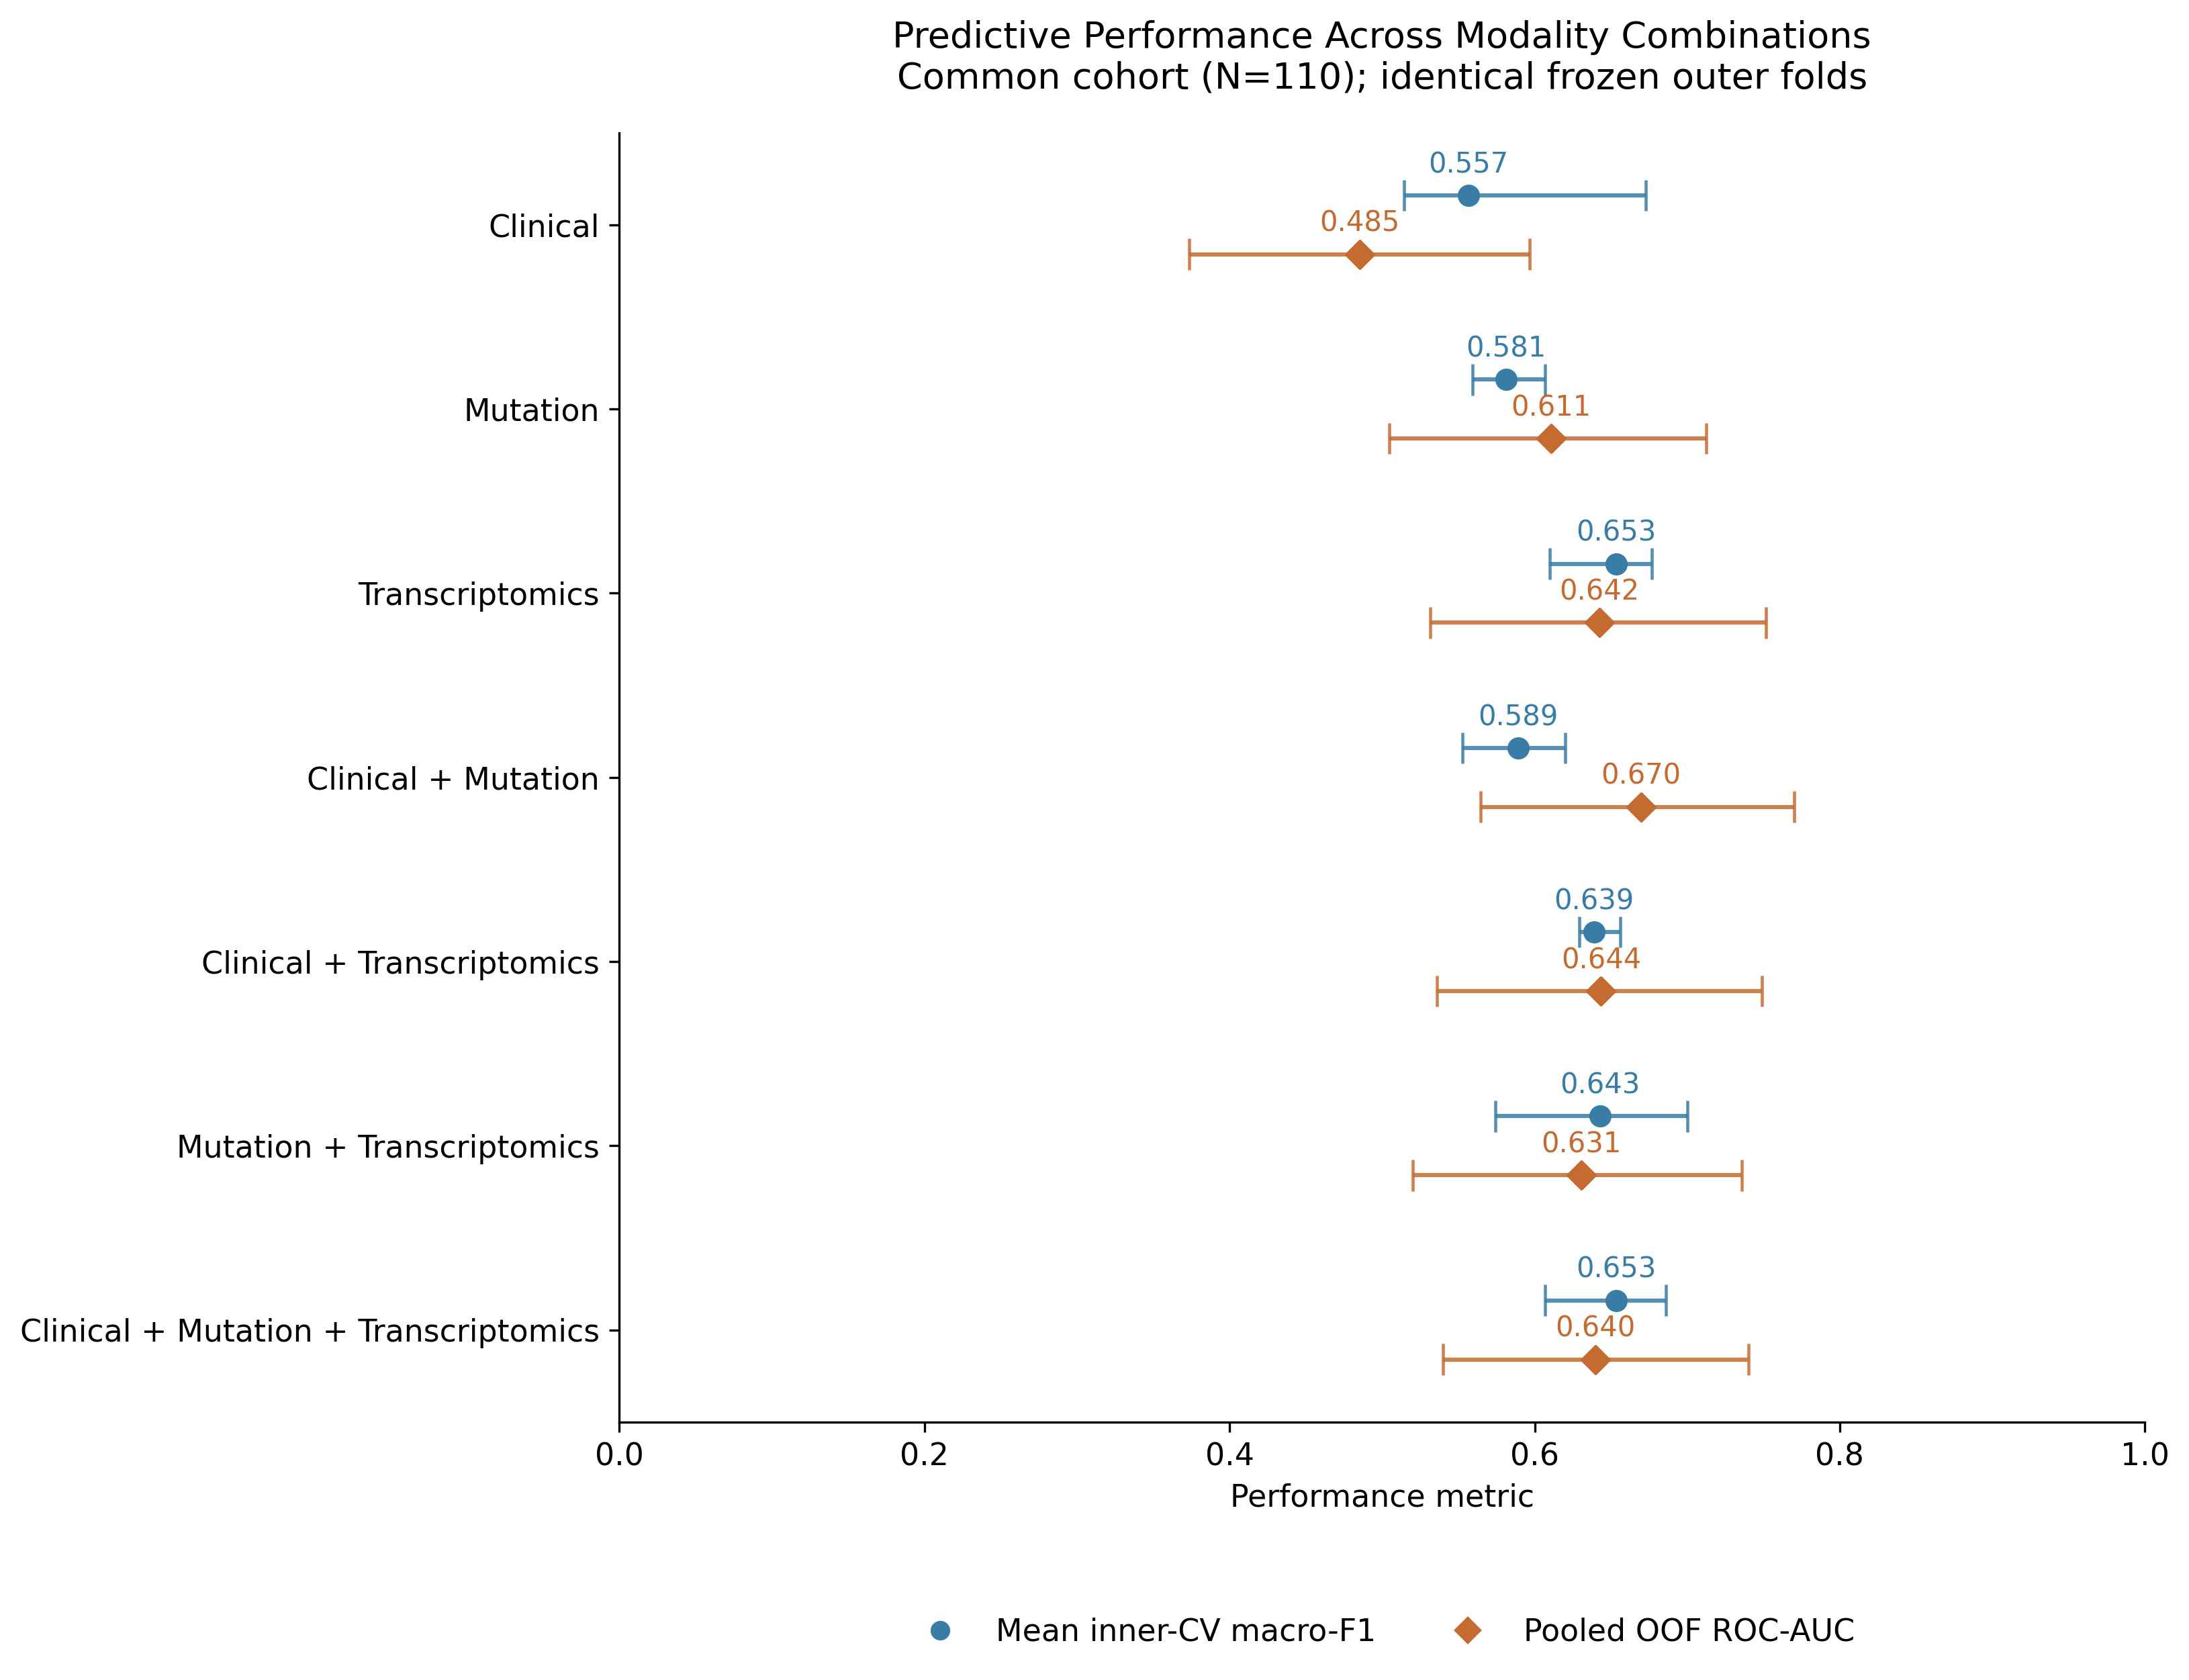

In [2]:
figure_dir = p110_repo / 'figures/results/common_cohort'
figure_dir.mkdir(parents=True, exist_ok=True)
figure_png = figure_dir / 'common_cohort_overview_inner_range_pooled_bootstrap_ci.png'
figure_pdf = figure_dir / 'common_cohort_overview_inner_range_pooled_bootstrap_ci.pdf'
summary = pd.read_csv(Path('/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/Common-Cohort-Modality-Comparison/common_cohort_selected_models_summary_statistics.csv')).set_index('configuration')
folds = pd.read_csv(Path('/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/Common-Cohort-Modality-Comparison/common_cohort_selected_models_fold_values.csv'))
order = ['clinical', 'mutation', 'transcriptomics', 'clinical_mutation', 'clinical_transcriptomics', 'mutation_transcriptomics', 'clinical_mutation_transcriptomics']
labels = ['Clinical', 'Mutation', 'Transcriptomics', 'Clinical + Mutation', 'Clinical + Transcriptomics', 'Mutation + Transcriptomics', 'Clinical + Mutation + Transcriptomics']
ci_source = Path('/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/Common-Cohort-Modality-Comparison/common_cohort_performance_summary.csv')
ci_table = pd.read_csv(ci_source)
ci_table = ci_table.loc[ci_table.selected_by_inner_cv].set_index('modality')
assert len(ci_table) == 7 and ci_table.N.eq(110).all()
assert ci_table.bootstrap_valid.eq(2000).all() and ci_table.bootstrap_seed.eq(42).all()
family_labels = {'logreg_l2': 'L2 logistic regression', 'random_forest': 'Random Forest', 'xgboost': 'XGBoost'}
with plt.rc_context({'font.family': 'DejaVu Sans', 'font.size': 11}):
    fig, ax = plt.subplots(figsize=(11, 8.5))
    for row, configuration in enumerate(order):
        values = folds[folds.configuration.eq(configuration)].sort_values('outer_fold')
        assert len(values) == 5 and set(values.outer_fold) == {1, 2, 3, 4, 5}
        for column, key, prefix, offset, color, marker in [
            ('inner_macro_f1', 'inner_mean', 'inner', -.16, '#397ca5', 'o'),
            ('outer_test_roc_auc', 'pooled_oof_roc_auc', 'outer', .16, '#c46b32', 'D'),
        ]:
            if prefix == 'inner':
                lo, hi = summary.loc[configuration, ['inner_min', 'inner_max']]
                np.testing.assert_allclose([lo, hi], [values[column].min(), values[column].max()], rtol=0, atol=1e-14)
            else:
                saved_ci = ci_table.loc[labels[row]]
                assert saved_ci.classifier == family_labels[summary.loc[configuration, 'family']]
                np.testing.assert_allclose(saved_ci.pooled_oof_auc, summary.loc[configuration, key], rtol=0, atol=1e-14)
                lo, hi = saved_ci[['pooled_auc_ci_lower', 'pooled_auc_ci_upper']]
            value = summary.loc[configuration, key]
            y = row + offset
            # Blue bars: inner-fold-score range. Orange bars: pooled-AUC patient bootstrap CI.
            ax.hlines(y, lo, hi, color=color, linewidth=1.5, alpha=.85, zorder=1)
            ax.vlines([lo, hi], y-.085, y+.085, color=color, linewidth=1.1, alpha=.85, zorder=1)
            ax.scatter([value], [y], color=color, marker=marker, s=48, zorder=3)
            ax.annotate(f'{value:.3f}', (value, y), xytext=(0, 6), textcoords='offset points', ha='center', va='bottom', fontsize=10, color=color)
    ax.set(yticks=np.arange(7), yticklabels=labels, xlabel='Performance metric', xlim=(0, 1), ylim=(6.5, -.5))
    ax.set_title('Predictive Performance Across Modality Combinations\nCommon cohort (N=110); identical frozen outer folds', fontsize=13, pad=16)
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(False)
    ax.legend(handles=[
        Line2D([], [], color='#397ca5', marker='o', linestyle='none', label='Mean inner-CV macro-F1'),
        Line2D([], [], color='#c46b32', marker='D', linestyle='none', label='Pooled OOF ROC-AUC'),
    ], loc='upper center', bbox_to_anchor=(.5, -.13), ncol=2, frameon=False)
    fig.tight_layout()
    fig.savefig(figure_png, dpi=300, bbox_inches='tight')
    fig.savefig(figure_pdf, bbox_inches='tight')
    plt.show()


Predictive performance across the seven input configurations in the common cohort (N=110), using identical frozen outer-fold assignments.

- **Blue circles:** mean inner-CV macro-F1, the predefined model-selection criterion. Blue bars span the minimum to maximum of the five outer-fold inner-CV macro-F1 values.
- **Orange diamonds:** pooled out-of-fold ROC-AUC from the concatenated held-out predictions. Orange bars show the 95% percentile bootstrap confidence interval from 2,000 paired patient-level resamples (seed 42).

These intervals are conditional on the saved out-of-fold predictions; they do not include model-refitting or model-selection uncertainty.

## Paired performance contexts

For the three single modalities, each metric is shown for the full-availability cohort and for the common cohort (N=110). Model families are selected by mean inner-CV macro-F1 within each context. Differences between contexts involve preprocessing and search spaces as well as cohort membership; they cannot be attributed solely to sample size.

In [3]:
p110_summary_contexts = []
for p110_config in ['clinical', 'mutation', 'transcriptomics']:
    p110_frame = p110_pd.read_csv(p110_root / 'primary_110' / p110_config / f'{p110_config}_primary_110_context_comparison.csv')
    p110_frame['Context'] = [f'Full availability (N={int(p110_frame.iloc[0].N)})', 'Common cohort (N=110)']
    p110_frame['Input'] = p110_config
    p110_summary_contexts.append(p110_frame.drop(columns='analysis_context'))
p110_paired = p110_pd.concat(p110_summary_contexts,ignore_index=True)
thesis_display(p110_paired.set_index(['Input','Context']))

N     selected_family  \
Input           Context                                              
clinical        Full availability (N=149)  149             xgboost   
                Common cohort (N=110)      110           logreg_l2   
mutation        Full availability (N=112)  112       random_forest   
                Common cohort (N=110)      110       random_forest   
transcriptomics Full availability (N=139)  139  gene_level_xgboost   
                Common cohort (N=110)      110       random_forest   

                                          mean_inner_macro_f1 roc_auc  \
Input           Context                                                 
clinical        Full availability (N=149)               0.587   0.474   
                Common cohort (N=110)                   0.557   0.485   
mutation        Full availability (N=112)               0.663   0.572   
                Common cohort (N=110)                   0.581   0.611   
transcriptomics Full availability (N=139)               0.696   0.602   
                Common cohort (N=110)                   0.653   0.642   

                                          average_precision balanced_accuracy  \
Input           Context                                                         
clinical        Full availability (N=149)             0.544             0.485   
                Common cohort (N=110)                 0.644             0.506   
mutation        Full availability (N=112)             0.729             0.552   
                Common cohort (N=110)                 0.746             0.594   
transcriptomics Full availability (N=139)             0.684             0.558   
                Common cohort (N=110)                 0.717             0.601   

                                          macro_f1 precision sensitivity  \
Input           Context                                                    
clinical        Full availability (N=149)    0.485     0.558       0.565   
                Common cohort (N=110)        0.497     0.615       0.478   
mutation        Full availability (N=112)    0.546     0.655       0.559   
                Common cohort (N=110)        0.542     0.758       0.373   
transcriptomics Full availability (N=139)    0.558     0.659       0.635   
                Common cohort (N=110)        0.600     0.675       0.806   

                                          specificity brier_score  
Input           Context                                            
clinical        Full availability (N=149)       0.406       0.284  
                Common cohort (N=110)           0.535       0.368  
mutation        Full availability (N=112)       0.545       0.245  
                Common cohort (N=110)           0.814       0.233  
transcriptomics Full availability (N=139)       0.481       0.244  
                Common cohort (N=110)           0.395       0.225